In [1]:
from datetime import datetime
import pandas as pd
import requests


def convertTimeStampToUTC(data):
    from datetime import datetime
    return datetime.fromtimestamp(data)


def getURL(apiKey, cryptoSymbol, frequency, timestamp, MaxRecordsToGetOnEachCall):
    API_KEY = '&api_key='+str(apiKey)
    limit = '&limit='+str(MaxRecordsToGetOnEachCall)
    cryptoHeader = 'fsym='+str(cryptoSymbol)
    ouputCurrency = '&tsym=USD'

    if (timestamp == ""):
        url = 'https://min-api.cryptocompare.com/data/v2/histo'+frequency+'?'+cryptoHeader
    else:
        url = 'https://min-api.cryptocompare.com/data/v2/histo' + \
            frequency+'?'+cryptoHeader+'&toTs='+str(timestamp)

    return url+ouputCurrency+API_KEY+limit


def getCryptoData(apikey, crypto, frequency, numOfTimesToHitApi, MaxRecordsToGetOnEachCall):
    numOfTimesToHitApi = 5
    data = pd.DataFrame()
    nextTimeStamp = 0

    for i in range(0, numOfTimesToHitApi):
        if (nextTimeStamp == 0):
            url = getURL(apikey, crypto, frequency,
                         "", MaxRecordsToGetOnEachCall)
        else:
            url = getURL(apikey, crypto, frequency,
                         nextTimeStamp, MaxRecordsToGetOnEachCall)

        response = requests.get(url).json()
        partialData = pd.DataFrame(response.get('Data').get('Data'))
        nextTimeStamp = partialData['time'].min()-1
        data = pd.concat([data, partialData])

    data = data.sort_values(by=['time'], ignore_index=True)
    data['timeUTC'] = data['time'].apply(convertTimeStampToUTC)
    data = data.reset_index(drop=True)
    return data

In [1]:
print("hello")

hello


In [2]:
# Parameters To Scrape Any Bitcoin Data

# API_KEY: Create a trial account on https://min-api.cryptocompare.com/ and create a API_KEY (Its free)
# Valid Values for crypto: BTC | ETH | XRP | BCH | BSV | LTC | EOS | XMR | ADA and Many More
# numOfTimesToHitApi: For Trial Account this is somwhere 1000 per second, which is sufficient here
# MaxRecordsToGetOnEachCall: Max is 2000
# frequency : Valid Options are  day|hour|minute

API_KEY = "fa4624d419a47099a289a342516cca60ce281178eef89da3f672c1f15ec54d92"
crypto = "BTC"
numOfTimesToHitApi = 5
MaxRecordsToGetOnEachCall = 200
frequency = "hour"

cryptoData = getCryptoData(API_KEY, crypto, frequency,
                           numOfTimesToHitApi, MaxRecordsToGetOnEachCall)
cryptoData

,time,high,low,open,volumefrom,volumeto,close,conversionType,conversionSymbol,timeUTC
0,1774083600,70729.97,70567.39,70587.00,520.200,36756529.43,70651.77,direct,,2026-03-21 14:30:00
1,1774087200,70686.22,70554.46,70651.77,212.690,15015712.52,70598.01,direct,,2026-03-21 15:30:00
2,1774090800,70641.20,70558.71,70598.01,138.830,9801713.45,70639.50,direct,,2026-03-21 16:30:00
3,1774094400,70783.88,70639.45,70639.50,218.870,15477909.68,70702.56,direct,,2026-03-21 17:30:00
4,1774098000,70799.93,70688.52,70702.56,222.820,15760254.77,70720.86,direct,,2026-03-21 18:30:00
...,...,...,...,...,...,...,...,...,...,...
1000,1777683600,78433.52,78295.13,78344.98,275.240,21563617.82,78341.43,direct,,2026-05-02 06:30:00
1001,1777687200,78507.28,78256.85,78341.43,326.500,25588453.28,78363.64,direct,,2026-05-02 07:30:00
1002,1777690800,78516.70,78238.05,78363.64,302.950,23741414.82,78414.06,direct,,2026-05-02 08:30:00
1003,1777694400,78445.80,78124.29,78414.06,359.750,28154256.92,78177.69,direct,,2026-05-02 09:30:00


In [3]:
cryptoData.to_csv("btc.csv")

In [ ]:
# Parameters To Scrape Any Bitcoin Data

# API_KEY: Create a trial account on https://min-api.cryptocompare.com/ and create a API_KEY (Its free)
# Valid Values for crypto: BTC | ETH | XRP | BCH | BSV | LTC | EOS | XMR | ADA and Many More
# numOfTimesToHitApi: For Trial Account this is somwhere 1000 per second, which is sufficient here
# MaxRecordsToGetOnEachCall: Max is 2000
# frequency : Valid Options are  day|hour|minute

API_KEY = "fa4624d419a47099a289a342516cca60ce281178eef89da3f672c1f15ec54d92"
crypto = "ETH"
numOfTimesToHitApi = 5
MaxRecordsToGetOnEachCall = 200
frequency = "hour"

cryptoData = getCryptoData(API_KEY, crypto, frequency,
                           numOfTimesToHitApi, MaxRecordsToGetOnEachCall)
cryptoData

In [4]:
cryptoData.to_csv("ETH.csv")

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Bidirectional, GRU, Dense
from sklearn.model_selection import train_test_split

# Load the data


def closedata(data):
    data = pd.read_csv(data)

    # Use only the 'close' column
    data = data[['close']]

    # Normalize the data
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data)

    # Function to create sequences for the BiGRU model
    def create_sequences(data, time_steps):
        x, y = [], []
        for i in range(len(data) - time_steps):
            x.append(data[i:(i + time_steps), 0])
            y.append(data[i + time_steps, 0])
        return np.array(x), np.array(y)

    # Define the time steps and create sequences
    time_steps = 10  # Adjust as needed
    x, y = create_sequences(data_scaled, time_steps)

    # Split the data into training and testing sets
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42)

    # Reshape the data for input to BiGRU
    x_train = x_train.reshape(x_train.shape[0], x_train.shape[1], 1)
    x_test = x_test.reshape(x_test.shape[0], x_test.shape[1], 1)

    # Build the BiGRU model
    model = Sequential()
    model.add(Bidirectional(GRU(units=50, activation='relu',
                                input_shape=(x_train.shape[1], 1))))
    model.add(Dense(units=1))
    model.compile(optimizer='adam', loss='mean_squared_error')

    # Train the model
    model.fit(x_train, y_train, epochs=50, batch_size=32, verbose=0)

    # Evaluate the model
    train_loss = model.evaluate(x_train, y_train, verbose=0)
    test_loss = model.evaluate(x_test, y_test, verbose=0)

    # Display the training and testing loss
    print("Training Loss:", train_loss)
    print("Testing Loss:", test_loss)

    # Future Predictions
    future_predictions = []
    future_sequence = data_scaled[-time_steps:].reshape(1, time_steps, 1)
    num_predictions = 10  # Adjust as needed

    for _ in range(num_predictions):
        next_prediction = model.predict(future_sequence)
        future_predictions.append(next_prediction[0, 0])
        future_sequence = np.append(future_sequence[:, 1:, :], np.array(
            [[next_prediction[0, 0]]]).reshape(1, 1, 1), axis=1)

    # Inverse transform the future predictions
    future_predictions = scaler.inverse_transform(
        np.array(future_predictions).reshape(-1, 1))
    print(future_predictions)
    # Plotting
    plt.figure(figsize=(12, 6))
    plt.plot(data.index, scaler.inverse_transform(
        data_scaled), label='Actual Close Prices')
    future_index = range(len(data_scaled), len(data_scaled) + num_predictions)
    plt.plot(future_index, future_predictions,
             label='Future Predictions', linestyle='dashed')
    plt.xlabel('Time')
    plt.ylabel('Close Price')
    plt.legend()
    plt.show()

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Bidirectional, GRU, Dense
from sklearn.model_selection import train_test_split

# Load the data


def opendata(data):
    data = pd.read_csv(data)

    # Use only the 'close' column
    data = data[['open']]

    # Normalize the data
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data)

    # Function to create sequences for the BiGRU model
    def create_sequences(data, time_steps):
        x, y = [], []
        for i in range(len(data) - time_steps):
            x.append(data[i:(i + time_steps), 0])
            y.append(data[i + time_steps, 0])
        return np.array(x), np.array(y)

    # Define the time steps and create sequences
    time_steps = 10  # Adjust as needed
    x, y = create_sequences(data_scaled, time_steps)

    # Split the data into training and testing sets
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42)

    # Reshape the data for input to BiGRU
    x_train = x_train.reshape(x_train.shape[0], x_train.shape[1], 1)
    x_test = x_test.reshape(x_test.shape[0], x_test.shape[1], 1)

    # Build the BiGRU model
    model = Sequential()
    model.add(Bidirectional(GRU(units=50, activation='relu',
                                input_shape=(x_train.shape[1], 1))))
    model.add(Dense(units=1))
    model.compile(optimizer='adam', loss='mean_squared_error')

    # Train the model
    model.fit(x_train, y_train, epochs=50, batch_size=32, verbose=0)

    # Evaluate the model
    train_loss = model.evaluate(x_train, y_train, verbose=0)
    test_loss = model.evaluate(x_test, y_test, verbose=0)

    # Display the training and testing loss
    print("Training Loss:", train_loss)
    print("Testing Loss:", test_loss)

    # Future Predictions
    future_predictions = []
    future_sequence = data_scaled[-time_steps:].reshape(1, time_steps, 1)
    num_predictions = 10  # Adjust as needed

    for _ in range(num_predictions):
        next_prediction = model.predict(future_sequence)
        future_predictions.append(next_prediction[0, 0])
        future_sequence = np.append(future_sequence[:, 1:, :], np.array(
            [[next_prediction[0, 0]]]).reshape(1, 1, 1), axis=1)
    print(future_predictions)
    # Inverse transform the future predictions
    future_predictions = scaler.inverse_transform(
        np.array(future_predictions).reshape(-1, 1))

    # Plotting
    plt.figure(figsize=(12, 6))
    plt.plot(data.index, scaler.inverse_transform(
        data_scaled), label='Actual Close Prices')
    future_index = range(len(data_scaled), len(data_scaled) + num_predictions)
    plt.plot(future_index, future_predictions,
             label='Future Predictions', linestyle='dashed')
    plt.xlabel('Time')
    plt.ylabel('Close Price')
    plt.legend()
    plt.show()

Training Loss: 0.0008609493961557746
Testing Loss: 0.0014029019512236118
1/1 [==============================] - 0s 62ms/step
[[81797.41 ]
 [81812.695]
 [81845.9  ]
 [81884.945]
 [81928.164]
 [81968.9  ]
 [82004.195]
 [82036.336]
 [82075.94 ]
 [82112.234]]


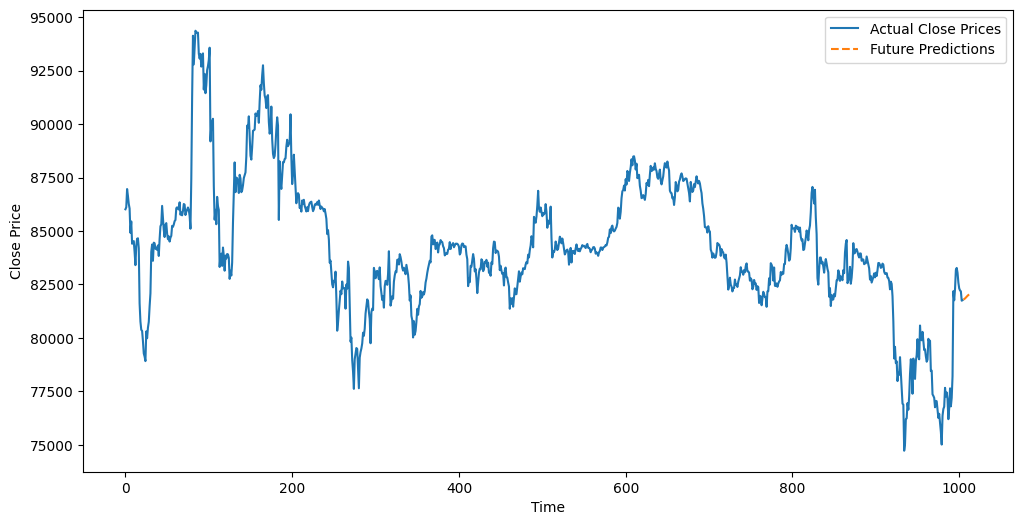

In [5]:
closedata("btc.csv")

Training Loss: 0.0008749635308049619
Testing Loss: 0.0008137924014590681
1/1 [==============================] - 0s 37ms/step
[[71496.7  ]
 [71295.65 ]
 [71032.43 ]
 [70736.33 ]
 [70444.125]
 [70172.66 ]
 [69930.29 ]
 [69715.75 ]
 [69518.32 ]
 [69335.11 ]]


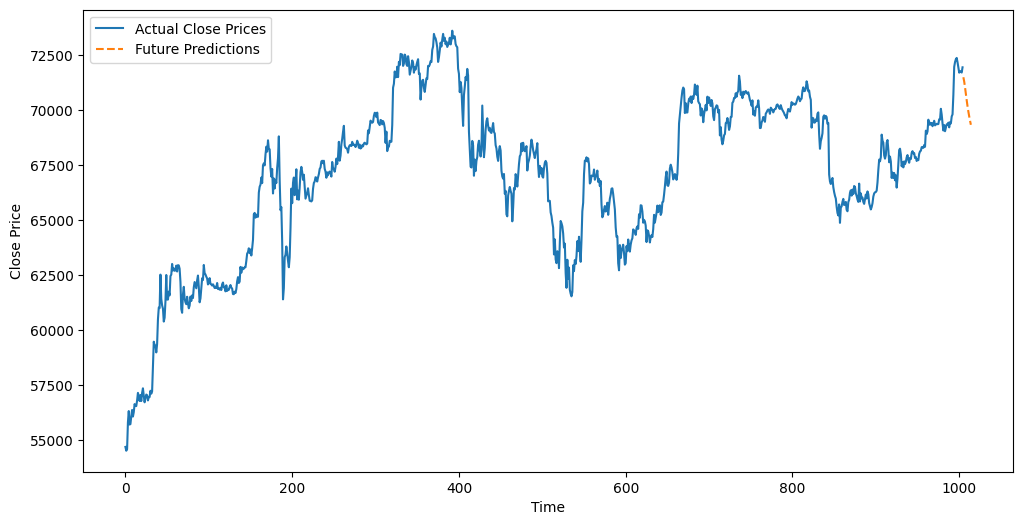

In [6]:
closedata("eth.csv")

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Bidirectional, LSTM, GRU, Dense
from sklearn.model_selection import train_test_split


def closedata(file_path):
    data = pd.read_csv(file_path)

    # Use only 'close'
    data = data[['close']]

    # Normalize
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data)

    # Sequence creation
    def create_sequences(data, time_steps):
        x, y = [], []
        for i in range(len(data) - time_steps):
            x.append(data[i:i + time_steps, 0])
            y.append(data[i + time_steps, 0])
        return np.array(x), np.array(y)

    time_steps = 10
    x, y = create_sequences(data_scaled, time_steps)

    # ⚠️ Better split for time series (no shuffle)
    split = int(len(x) * 0.8)
    x_train, x_test = x[:split], x[split:]
    y_train, y_test = y[:split], y[split:]

    # Reshape
    x_train = x_train.reshape(x_train.shape[0], x_train.shape[1], 1)
    x_test = x_test.reshape(x_test.shape[0], x_test.shape[1], 1)

    # ---------------------------
    # 🔥 HYBRID MODEL
    # ---------------------------
    model = Sequential()

    # BiLSTM Layer
    model.add(Bidirectional(LSTM(64, return_sequences=True),
                            input_shape=(time_steps, 1)))

    # BiGRU Layer
    model.add(Bidirectional(GRU(32)))

    # Output
    model.add(Dense(1))

    model.compile(optimizer='adam', loss='mse')

    # Train
    model.fit(x_train, y_train, epochs=40, batch_size=32, verbose=1)

    # Evaluate
    print("\nTraining Loss:", model.evaluate(x_train, y_train, verbose=0))
    print("Testing Loss :", model.evaluate(x_test, y_test, verbose=0))

    # ---------------------------
    # Future Prediction
    # ---------------------------
    future_sequence = data_scaled[-time_steps:].reshape(1, time_steps, 1)
    future_predictions = []
    num_predictions = 10

    for _ in range(num_predictions):
        pred = model.predict(future_sequence, verbose=0)
        future_predictions.append(pred[0, 0])

        future_sequence = np.append(
            future_sequence[:, 1:, :],
            [[[pred[0, 0]]]],
            axis=1
        )

    # Inverse transform
    future_predictions = scaler.inverse_transform(
        np.array(future_predictions).reshape(-1, 1))

    print("\nFuture Predictions:\n", future_predictions)

    # ---------------------------
    # Plot
    # ---------------------------
    plt.figure(figsize=(12, 6))
    plt.plot(data.index, scaler.inverse_transform(data_scaled),
             label='Actual')

    future_index = range(len(data_scaled), len(data_scaled) + num_predictions)
    plt.plot(future_index, future_predictions,
             linestyle='dashed', label='Hybrid Forecast')

    plt.legend()
    plt.show()

Epoch 1/40
25/25 [==============================] - 8s 13ms/step - loss: 0.0380
Epoch 2/40
25/25 [==============================] - 0s 13ms/step - loss: 0.0049
Epoch 3/40
25/25 [==============================] - 0s 13ms/step - loss: 0.0038
Epoch 4/40
25/25 [==============================] - 0s 13ms/step - loss: 0.0034
Epoch 5/40
25/25 [==============================] - 0s 13ms/step - loss: 0.0033
Epoch 6/40
25/25 [==============================] - 0s 13ms/step - loss: 0.0031
Epoch 7/40
25/25 [==============================] - 0s 13ms/step - loss: 0.0029
Epoch 8/40
25/25 [==============================] - 0s 13ms/step - loss: 0.0027
Epoch 9/40
25/25 [==============================] - 0s 14ms/step - loss: 0.0026
Epoch 10/40
25/25 [==============================] - 0s 14ms/step - loss: 0.0025
Epoch 11/40
25/25 [==============================] - 0s 17ms/step - loss: 0.0023
Epoch 12/40
25/25 [==============================] - 0s 14ms/step - loss: 0.0022
Epoch 13/40
25/25 [==================

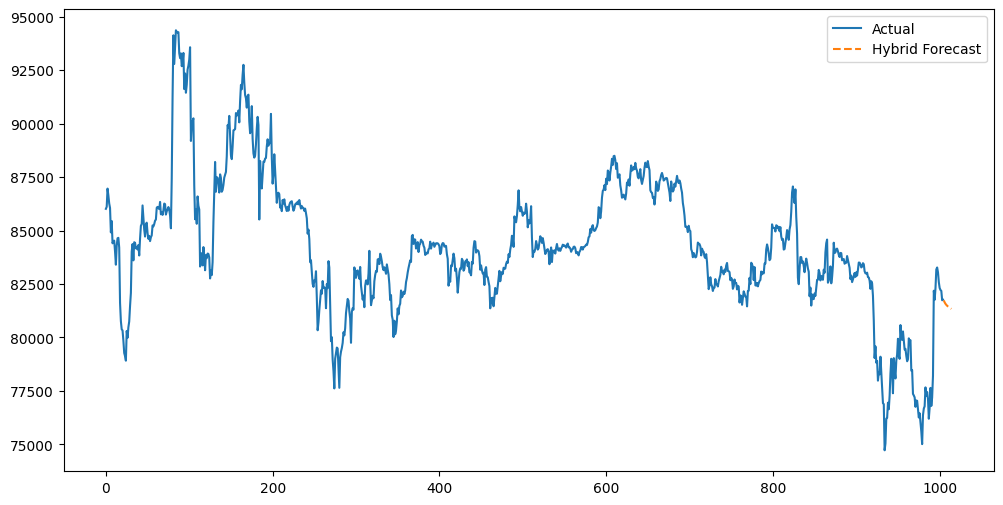

In [8]:
# Example usage
closedata("btc.csv")